In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import seaborn as sns
from tqdm import trange
from itertools import product
import openpyxl
from sklearn.cluster import KMeans


In [2]:
def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

## 10. Introduce n_g as a parameter




In [3]:
def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    W_g_r = jnp.array([[0.0, theta[10]], [theta[10], 0.0]])
    W_g_y = jnp.array([[0.0, theta[11]], [theta[11], 0.0]])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


In [4]:

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g_val)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-8, maxiter=100)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values (n_g is now part of theta)
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 11. Random initialisations and Adam optimisation to hit output targets


In [5]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# Hard-coded targets
t_op_low_y = 0.2   # x=0.5: only mitral (y) in the loss; r,g,b free at this op
t_op_high = 0.5    # x=1.0: r, g, b, y all trained to this

# Operating point 1: input x = 0.5 (y only — used in loss_fn)
x1 = jnp.ones(m) * 0.5
y_target1 = jnp.ones(m) * t_op_low_y

# Operating point 2: input x = 1.0 (full r,g,b,y)
x2 = jnp.ones(m) * 1.0
y_target2 = jnp.ones(m) * t_op_high
g_target2 = jnp.ones(m) * t_op_high
b_target2 = jnp.ones(m) * t_op_high
r_target2 = jnp.ones(m) * t_op_high

val_tol = 0.1  # acceptance band (op1: y only; op2: r,g,b,y)

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y, n_g
no_params = 13  # total number of parameters (n_g is now tunable at index 12)

n_g_default = 1.868  # default n_g value for initialisation and clipping

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Operating point 1 — x=0.5: loss on mitral (y) only, target y = {t_op_low_y}")
print(f"  - Operating point 2 — x=1.0: targets r,g,b,y = {t_op_high}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g(default)={n_g_default}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 13
  - Operating point 1 — x=0.5: loss on mitral (y) only, target y = 0.2
  - Operating point 2 — x=1.0: targets r,g,b,y = 0.5
  - N values: n_r=1.85, n_b=0.642, n_g(default)=1.868, n_y=1.562


In [6]:
# define loss function (sum over both operating points)
def loss_fn(theta):
    """Op1 (x=0.5): only mitral y to t_op_low_y. Op2 (x=1.0): r,g,b,y to t_op_high."""
    r1, g1, b1, y1 = mitral_output(theta, x1, m, n_r=n_r, n_b=n_b, n_y=n_y)
    r2, g2, b2, y2 = mitral_output(theta, x2, m, n_r=n_r, n_b=n_b, n_y=n_y)
    loss1 = jnp.sum((y1 - y_target1) ** 2)
    loss2 = (jnp.sum((r2 - r_target2) ** 2) +
             jnp.sum((g2 - g_target2) ** 2) +
             jnp.sum((b2 - b_target2) ** 2) +
             jnp.sum((y2 - y_target2) ** 2))
    return loss1 + loss2


In [7]:
def adam_optimiser(
    loss_fn,
    theta_init,
    lr=0.03,
    steps=800,#1200,
    beta1=0.9,
    beta2=0.99,
    eps=1e-6,
    max_grad_norm=3.0,
    loss_tol=0,
    use_lr_schedule=True,
    log_every=20,
):
    """
    Adam optimiser (optax) with gradient clipping, optional LR decay, and early stopping.

    LR schedule (when use_lr_schedule=True): lr -> 0.1*lr at step 400 -> 0.01*lr at step 800.
    Stops early when loss < loss_tol (default 1e-6).
    """
    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    if use_lr_schedule:
        learning_rate = optax.piecewise_constant_schedule(
            init_value=lr,
            boundaries_and_scales={400: 0.1, 800: 0.1},
        )
    else:
        learning_rate = lr

    optimizer = optax.chain(
        optax.clip_by_global_norm(max_grad_norm),
        optax.adam(learning_rate=learning_rate, b1=beta1, b2=beta2, eps=eps),
    )
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init
    alpha_start_idx = 9
    alpha_end_idx = 10

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        theta = jnp.clip(theta, 0.0, None)
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )

        loss_float = float(loss_fn_jit(theta))
        if step % log_every == 0 or step == steps - 1:
            loss_history.append(loss_float)
        if loss_float < loss_tol:
            if step % log_every != 0 and step != steps - 1:
                loss_history.append(loss_float)
            break

    return theta, loss_history

In [8]:
# sample initial parameters
no_samples = 1000 # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 1000 initial parameter sets
Initial parameter matrix shape: (1000, 13)


In [11]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt1 = jnp.zeros((no_samples, m))
g_opt1 = jnp.zeros((no_samples, m))
b_opt1 = jnp.zeros((no_samples, m))
y_opt1 = jnp.zeros((no_samples, m))
r_opt2 = jnp.zeros((no_samples, m))
g_opt2 = jnp.zeros((no_samples, m))
b_opt2 = jnp.zeros((no_samples, m))
y_opt2 = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_unpacked = unpack_theta(theta_matrix[i, :], m)
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r1, g1, b1, y1 = mitral_output(theta_optimised, x1, m, n_r=n_r, n_b=n_b, n_y=n_y)
    r2, g2, b2, y2 = mitral_output(theta_optimised, x2, m, n_r=n_r, n_b=n_b, n_y=n_y)

    r_opt1 = r_opt1.at[i, :].set(r1)
    g_opt1 = g_opt1.at[i, :].set(g1)
    b_opt1 = b_opt1.at[i, :].set(b1)
    y_opt1 = y_opt1.at[i, :].set(y1)
    r_opt2 = r_opt2.at[i, :].set(r2)
    g_opt2 = g_opt2.at[i, :].set(g2)
    b_opt2 = b_opt2.at[i, :].set(b2)
    y_opt2 = y_opt2.at[i, :].set(y2)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y at x=0.5: {np.array(y1)}")
    print(f"  Output y at x=1.0: {np.array(y2)}")
    print()


Running Adam optimizer...

Sample 1/1000:
  Initial loss: 1.025859
  Final loss: 0.580000
  Output y at x=0.5: [0. 0.]
  Output y at x=1.0: [0. 0.]

Sample 2/1000:
  Initial loss: 1.708028
  Final loss: nan
  Output y at x=0.5: [nan nan]
  Output y at x=1.0: [nan nan]

Sample 3/1000:
  Initial loss: 1.823761
  Final loss: nan
  Output y at x=0.5: [nan nan]
  Output y at x=1.0: [nan nan]

Sample 4/1000:
  Initial loss: 1.236769
  Final loss: 0.500000
  Output y at x=0.5: [0.19999997 0.19999997]
  Output y at x=1.0: [0.50000006 0.50000006]

Sample 5/1000:
  Initial loss: 1.391965
  Final loss: 0.580000
  Output y at x=0.5: [0. 0.]
  Output y at x=1.0: [0. 0.]

Sample 6/1000:
  Initial loss: 1.396212
  Final loss: nan
  Output y at x=0.5: [nan nan]
  Output y at x=1.0: [nan nan]

Sample 7/1000:
  Initial loss: 1.260971
  Final loss: 1.080000
  Output y at x=0.5: [0. 0.]
  Output y at x=1.0: [0. 0.]

Sample 8/1000:
  Initial loss: 1.654673
  Final loss: nan
  Output y at x=0.5: [nan nan]
 

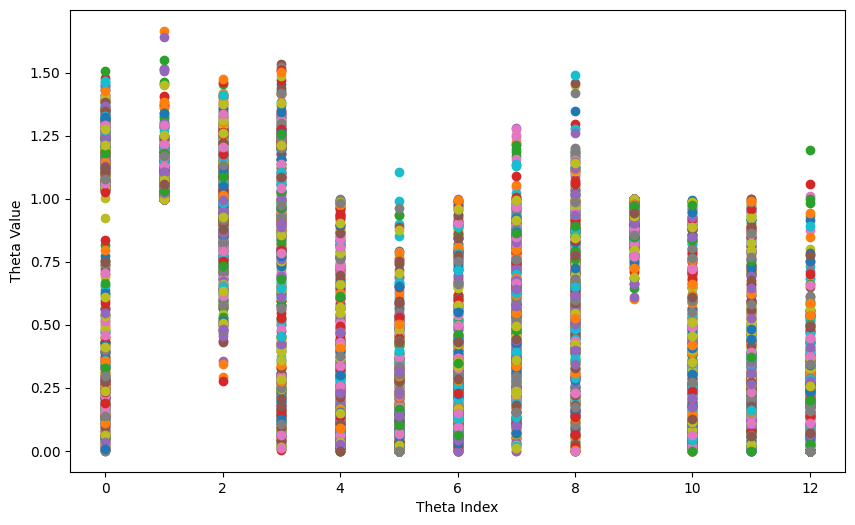

In [ ]:
theta_opt.shape
plt.figure(figsize=(10, 6))
for i in range(no_samples):
    plt.plot(theta_opt[i, :], 'o', label=f'Sample {i+1}')
plt.xlabel('Theta Index')
plt.ylabel('Theta Value')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


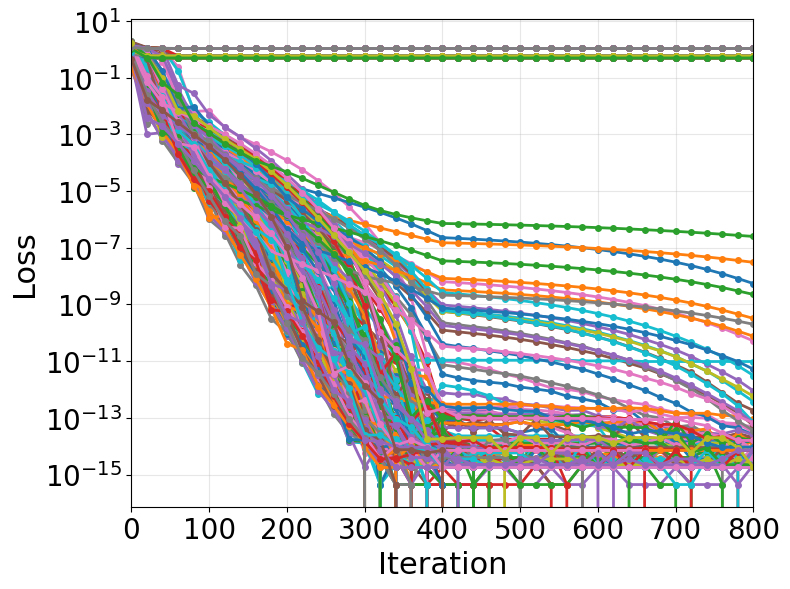

In [12]:
plt.figure(figsize=(8, 6))

# keep track of the line objects so we can get their colors
lines = []

for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  # store line object

plt.xlabel('Iteration', fontsize=22)
plt.ylabel('Loss', fontsize=22)
plt.yscale('log')
#plt.xlim(0, 500)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)

# create legend using the colors of the actual plotted lines
#legend_handles = [Patch(color=line.get_color(), label=f'Set {i+1}')
#                  for i, line in enumerate(lines)]
#plt.legend(handles=legend_handles,loc='upper right',  fontsize=18)

plt.xlim(0, 800)
plt.tight_layout()
plt.savefig('Figures_final/two_op_loss_convergence.eps')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


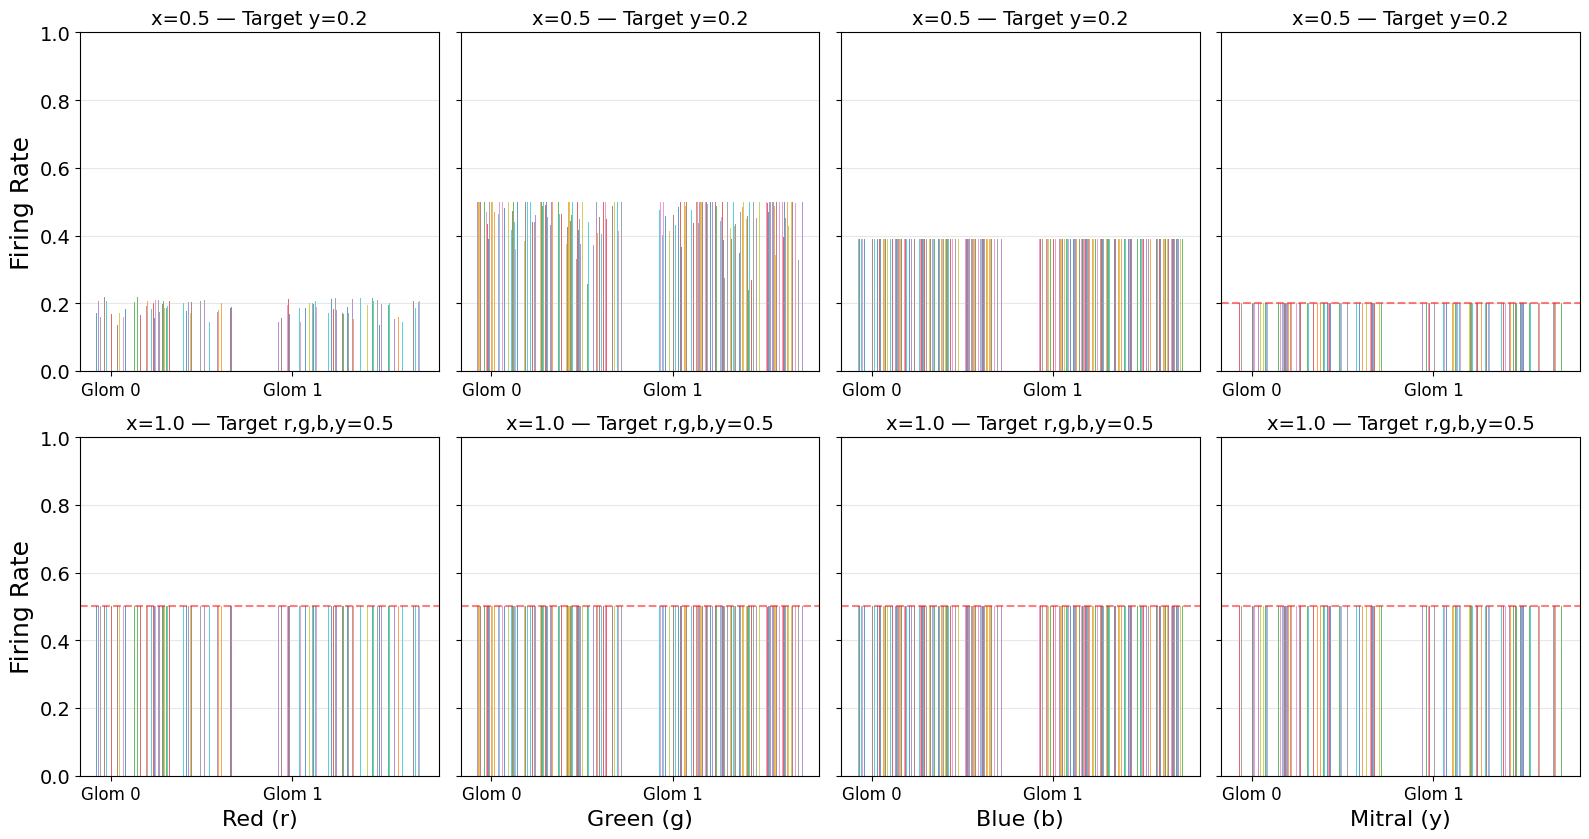

In [ ]:
###############################
# plot r, g, b, y for both operating points (rows: op1 x=0.5, op2 x=1.0)
plt.figure(figsize=(16, 10))

neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
op_rows = [
    ('x=0.5 — Target y=0.2', [r_opt1, g_opt1, b_opt1, y_opt1]),
    ('x=1.0 — Target r,g,b,y=0.5', [r_opt2, g_opt2, b_opt2, y_opt2]),
]

for row, (op_label, outputs_list) in enumerate(op_rows):
    for col, (neuron_type, output) in enumerate(zip(neuron_types, outputs_list)):
        ax_idx = row * 4 + col + 1
        plt.subplot(2, 4, ax_idx)

        x_pos = np.arange(m)
        width = 0.8 / y_opt1.shape[0]

        for i in range(y_opt1.shape[0]):
            plt.bar(x_pos + i * width, np.array(output[i]), width,
                    label=f'Sample {i+1}' if (row == 0 and col == 0) else '', alpha=0.7)

        if row == 0 and col == 3:
            plt.axhline(y=t_op_low_y, color='red', linestyle='--', linewidth=1.5,
                        alpha=0.5, label=f'y target ({t_op_low_y})')
        elif row == 1:
            plt.axhline(y=t_op_high, color='red', linestyle='--', linewidth=1.5,
                        alpha=0.5, label=f'Target ({t_op_high})')

        if col == 0:
            plt.ylabel('Firing Rate', fontsize=18)
            plt.tick_params(axis='y', labelsize=14)
        else:
            plt.tick_params(axis='y', labelleft=False)

        plt.xticks(x_pos + 100 * width, [f'Glom {j}' for j in range(m)], fontsize=12)
        if row == 1:
            plt.xlabel(f'{neuron_type}', fontsize=16)
        plt.title(f'{op_label}', fontsize=14)
        plt.ylim([0, 1.0])
        plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.savefig('Figures_final/two_op_neuron_outputs_rgby.eps')
plt.show()


In [ ]:
def check_single_theta_np(theta, m):
    """Op1: only y near t_op_low_y. Op2: r,g,b,y near t_op_high."""
    r1, g1, b1, y1 = mitral_output(theta, x1, m, n_r, n_b, n_y)
    r2, g2, b2, y2 = mitral_output(theta, x2, m, n_r, n_b, n_y)

    def ok_band(arr, t):
        arr = np.array(arr)
        return (arr >= t - val_tol).all() and (arr <= t + val_tol).all()

    op1_ok = ok_band(y1, t_op_low_y)
    op2_ok = (ok_band(r2, t_op_high) and ok_band(g2, t_op_high) and
              ok_band(b2, t_op_high) and ok_band(y2, t_op_high))
    return op1_ok and op2_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]
print(theta_opt.shape)

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

# save theta_opt as pickle file
os.makedirs('Theta_opt', exist_ok=True)
fn = f'Theta_opt/theta_opt_{theta_opt.shape[0]}_2_points_final.pkl'
print(fn)
with open(
    fn,
    'wb',
) as f:
    pickle.dump(theta_opt, f)

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
(214, 13)
Number of valid theta_opt: 214 out of 1000
Theta_opt/theta_opt_214_2_points_final.pkl
